## Klasifikasi Topik Artikel Komdigi dengan Naive Bayes

Notebook ini menerapkan Bag-of-Words dan Multinomial Naive Bayes pada artikel klarifikasi hoaks Komdigi. Teks dari `title`, `excerpt`, dan `body_text` digunakan untuk memprediksi `topics`. `topics` adalah kategori artikel, bukan label benar atau salahnya klaim.


In [1]:
# Import library
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

In [2]:
# Cari dataset dari direktori kerja notebook hingga root proyek.
data_path = next(
    (
        parent / "data" / "komdigi_hoaks.csv"
        for parent in (Path.cwd(), *Path.cwd().parents)
        if (parent / "data" / "komdigi_hoaks.csv").is_file()
    ),
    None,
)
if data_path is None:
    raise FileNotFoundError("File data/komdigi_hoaks.csv tidak ditemukan dari direktori kerja saat ini.")

df = pd.read_csv(data_path)
required_columns = ["url", "title", "excerpt", "body_text", "topics"]
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError(f"Kolom wajib tidak ditemukan pada dataset: {missing_columns}")

# Hapus artikel duplikat, abaikan artikel tanpa label, dan gabungkan kolom teks.
df = df.drop_duplicates(subset="url", keep="first").dropna(subset=["topics"]).copy()
text_columns = ["title", "excerpt", "body_text"]
df[text_columns] = df[text_columns].fillna("").astype(str)
df["article_text"] = (
    df[text_columns]
    .agg(" ".join, axis=1)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
df = df.loc[df["article_text"].ne("")].reset_index(drop=True)

print(f"Lokasi dataset: {data_path.resolve()}")
print("Ukuran dataset setelah pembersihan:", df.shape)
display(df[["topics", "title", "excerpt"]].head())

Lokasi dataset: D:\Kuliah\Kelas\Semester 5\Pembelajaran Mesin\TUGAS\PRAKTIKUM\data\komdigi_hoaks.csv
Ukuran dataset setelah pembersihan: (4162, 14)


,topics,title,excerpt
0,Hoaks,[HOAKS] Tautan Pencairan BSU September 2026 Se...,Kepala Biro Humas Kementerian Ketenagakerjaan ...
1,Hoaks,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...,El Nino merupakan fenomena alam yang terjadi a...
2,Hoaks,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...,Maltodekstrin merupakan bahan tambahan pangan ...
3,Hoaks,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...,
4,Hoaks,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...,


Jumlah artikel per kelas:


,jumlah
topics,
Hoaks,3524
Penipuan,286
Pejabat Publik,135
Masyarakat Digital,102
Program/Kebijakan,59
Kesehatan,56



Nilai kosong pada kolom analisis:
article_text    0
topics          0
dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 4162 entries, 0 to 4161
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   id              4162 non-null   int64
 1   url             4162 non-null   str  
 2   title           4162 non-null   str  
 3   slug            4162 non-null   str  
 4   published_at    4162 non-null   str  
 5   view_count      4162 non-null   int64
 6   excerpt         4162 non-null   str  
 7   body_html       4162 non-null   str  
 8   body_text       4162 non-null   str  
 9   main_image_url  4157 non-null   str  
 10  category        4162 non-null   str  
 11  tags            2187 non-null   str  
 12  topics          4162 non-null   str  
 13  article_text    4162 non-null   str  
dtypes: int64(2), str(12)
memory usage: 17.5 MB


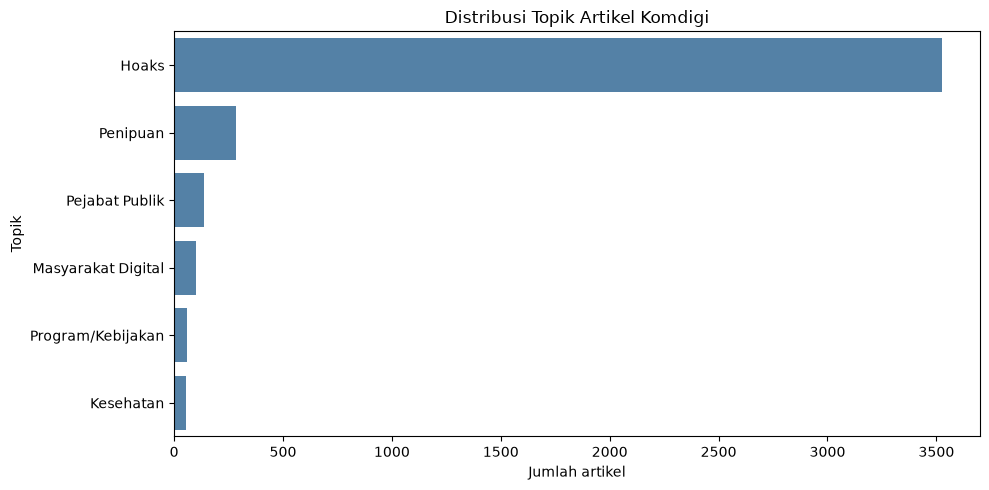

In [3]:
# Target topics sudah berupa label teks; tidak perlu diubah menjadi angka.
print("Jumlah artikel per kelas:")
display(df["topics"].value_counts().rename_axis("topics").to_frame("jumlah"))
print("\nNilai kosong pada kolom analisis:")
print(df[["article_text", "topics"]].isnull().sum())

df.info()

plt.figure(figsize=(10, 5))
class_order = df["topics"].value_counts().index
sns.countplot(data=df, y="topics", order=class_order, color="steelblue")
plt.title("Distribusi Topik Artikel Komdigi")
plt.xlabel("Jumlah artikel")
plt.ylabel("Topik")
plt.tight_layout()
plt.show()

In [4]:
# Artikel menjadi fitur teks dan topics menjadi label kelas.
X = df["article_text"]
y = df["topics"]
labels = sorted(y.unique())
print("Jumlah kelas:", len(labels))
print("Kelas:", labels)

Jumlah kelas: 6
Kelas: ['Hoaks', 'Kesehatan', 'Masyarakat Digital', 'Pejabat Publik', 'Penipuan', 'Program/Kebijakan']


In [5]:
# Bagi data 80:20 dengan menjaga proporsi kelas pada data latih dan uji.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

# Bag-of-Words menghitung kemunculan kata.
# Vocabulary dipelajari dari data latih saja untuk mencegah data leakage.
bow = CountVectorizer(
    max_features=20000,
    min_df=2,
    ngram_range=(1, 2),
)
X_train_bow = bow.fit_transform(X_train)
X_test_bow = bow.transform(X_test)

print("Ukuran X_train:", X_train_bow.shape)
print("Ukuran X_test:", X_test_bow.shape)
print("Ukuran y_train:", y_train.shape)
print("Ukuran y_test:", y_test.shape)

Ukuran X_train: (3329, 20000)
Ukuran X_test: (833, 20000)
Ukuran y_train: (3329,)
Ukuran y_test: (833,)


In [6]:
# Tampilkan ukuran kosakata serta beberapa token yang dipelajari.
feature_names = bow.get_feature_names_out()
print("Jumlah fitur/kosakata:", len(feature_names))
print("Contoh fitur:", feature_names[:30])
print(f"Dimensi matriks data latih: {X_train_bow.shape}")

Jumlah fitur/kosakata: 20000
Contoh fitur: ['00' '00 wib' '000' '000 000' '000 anak' '000 bagi' '000 dalam' '000 dan'
 '000 dari' '000 dollar' '000 faktanya' '000 https' '000 kali'
 '000 penjelasan' '000 per' '000 personel' '000 tidak' '000 triliun'
 '000 untuk' '000 yang' '01' '01 06' '01 08' '01 10' '01 17' '01 20'
 '01 21' '01 23' '01 24' '01 29']
Dimensi matriks data latih: (3329, 20000)


Akurasi data latih: 0.6981
Akurasi data uji: 0.6531
Macro F1-score data uji: 0.3227

Laporan klasifikasi data uji:
                    precision    recall  f1-score   support

             Hoaks       0.92      0.67      0.78       705
         Kesehatan       0.16      0.45      0.24        11
Masyarakat Digital       0.38      0.14      0.21        21
    Pejabat Publik       0.21      0.93      0.35        27
          Penipuan       0.25      0.70      0.37        57
 Program/Kebijakan       0.00      0.00      0.00        12

          accuracy                           0.65       833
         macro avg       0.32      0.48      0.32       833
      weighted avg       0.82      0.65      0.70       833



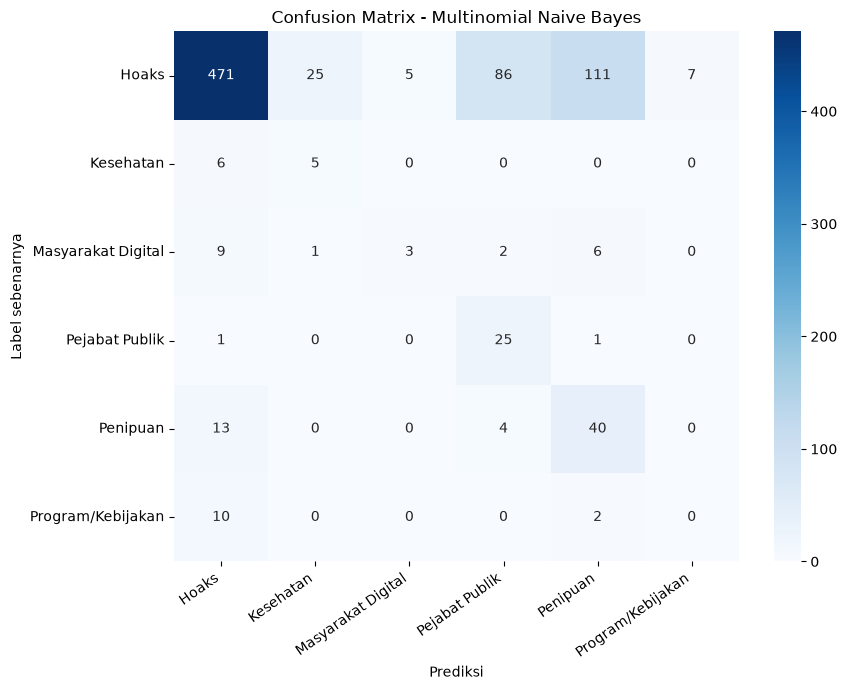

,title,topics_asli,topics_prediksi
2390,[HOAKS] AHY Berterima Kasih kepada Rakyat kare...,Hoaks,Hoaks
1181,[HOAKS] TNI Tangkap Anggota KKB dan WNA saat O...,Hoaks,Hoaks
1637,[HOAKS] Demonstrasi Menolak Aturan Pembatasan ...,Hoaks,Hoaks
2106,[HOAKS] Penggeledahan Apartemen Mantan Menteri...,Hoaks,Hoaks
631,[HOAKS] Kepala BP BUMN Umumkan Dana Bantuan un...,Hoaks,Hoaks
599,[HOAKS] Video Dedi Mulyadi Beri Bantuan Rp75 J...,Hoaks,Hoaks
2474,[HOAKS] Penyaluran Bansos dengan Tautan dan No...,Hoaks,Penipuan
554,[HOAKS] Pernyataan Wali Kota Sukabumi Terkait ...,Hoaks,Hoaks
3831,[HOAKS] Lowongan Pekerjaan Sebagai Analisis da...,Hoaks,Penipuan
3970,[HOAKS] Akun WhatsApp Mengatasnamakan Pegawai ...,Hoaks,Pejabat Publik


In [7]:
# Latih Multinomial Naive Bayes pada fitur Bag-of-Words.
mnb = MultinomialNB(alpha=0.5)
mnb.fit(X_train_bow, y_train)

y_pred_train = mnb.predict(X_train_bow)
y_pred_test = mnb.predict(X_test_bow)

print("Akurasi data latih:", round(accuracy_score(y_train, y_pred_train), 4))
print("Akurasi data uji:", round(accuracy_score(y_test, y_pred_test), 4))
print("Macro F1-score data uji:", round(f1_score(y_test, y_pred_test, average="macro", zero_division=0), 4))
print("\nLaporan klasifikasi data uji:")
print(
    classification_report(
        y_test,
        y_pred_test,
        labels=labels,
        target_names=labels,
        zero_division=0,
    )
)

cm = confusion_matrix(y_test, y_pred_test, labels=labels)
plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
)
plt.title("Confusion Matrix - Multinomial Naive Bayes")
plt.xlabel("Prediksi")
plt.ylabel("Label sebenarnya")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Contoh hasil prediksi pada artikel uji.
hasil_prediksi = df.loc[X_test.index, ["title", "topics"]].rename(
    columns={"topics": "topics_asli"}
).copy()
hasil_prediksi["topics_prediksi"] = y_pred_test
display(hasil_prediksi.head(10))